In [ ]:

# STEP 1: Import libraries and set up the Orange Classification project

from pathlib import Path
import zipfile

# Locate the uploaded ZIP file
ZIP_PATH = Path("/content/Orange Dataset.zip")

# Extract the dataset
EXTRACT_DIR = Path("/content/orange_extracted")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        "Orange Dataset.zip was not found. Check the Files panel."
    )

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Extracted to:", EXTRACT_DIR)

print("\nFirst 40 files and folders:")
for path in list(EXTRACT_DIR.rglob("*"))[:40]:
    print(path.relative_to(EXTRACT_DIR))



Dataset extracted successfully!
Extracted to: /content/orange_extracted

First 40 files and folders:
train
test
train/blackspot
train/grenning
train/canker
train/fresh
test/blackspot
test/grenning
test/canker
test/fresh
test/blackspot/b (22).jpg
test/blackspot/b (11).jpg
test/blackspot/b (6).jpg
test/blackspot/b (5).jpg
test/blackspot/b (18).jpg
test/blackspot/b (9).jpg
test/blackspot/b (19).jpg
test/blackspot/b (12).jpg
test/blackspot/b (17).jpg
test/blackspot/b (13).jpg
test/blackspot/b (7).jpg
test/blackspot/b (1).jpg
test/blackspot/b (21).jpg
test/blackspot/b (2).jpg
test/blackspot/b (20).jpg
test/blackspot/b (8).jpg
test/blackspot/b (15).jpg
test/blackspot/b (16).jpg
test/blackspot/b (3).jpg
test/blackspot/b (10).jpg
test/blackspot/b (14).jpg
test/blackspot/b (4).jpg
test/grenning/g (9).jpg
test/grenning/g (15).jpg
test/grenning/g (19).jpg
test/grenning/g (7).jpg
test/grenning/g (2).jpg
test/grenning/g (12).jpg
test/grenning/g (3).jpg
test/grenning/g (8).jpg


### Explanation: Dataset extraction

**Purpose:** Extract the uploaded ZIP archive so Python can access individual orange images.

**How it works:** `Path` defines file locations, `exists()` checks that the ZIP is present, `mkdir()` creates the destination folder, and `ZipFile(...).extractall(...)` extracts the archive. The final loop prints sample paths so the folder structure can be checked.

**Why this is needed:** The image-loading and feature-extraction code needs paths to actual image files, not just a compressed archive.

**Check the output:** Confirm that extraction completed and that the `train` and `test` folders appear.

**Purpose**: Prepare the Python environment and organize the project files.

The code imports libraries such as:
- os, shutil, zipfile: file and folder operations.
- Path: convenient path management.
- random, numpy: reproducible random operations and numerical processing.
- pandas: tabular data analysis.
- matplotlib: plots and visualizations.

The seed is set to 42:
SEED = 42random.seed(SEED)np.random.seed(SEED)



This helps make random operations reproducible. It does not guarantee that every operation in every library will be deterministic.

The directory setup creates locations for the dataset, reports, models, results, and source code.

Why it matters: A well-organized project is easier to debug, reproduce, and submit.

How to explain it in your walkthrough:
“First, I imported the required Python libraries and created separate folders for reports, trained models, results, and source code. I also set a random seed to improve reproducibility.”

In [ ]:

# Find the training and testing folders
train_candidates = [
    p for p in EXTRACT_DIR.rglob("*")
    if p.is_dir() and p.name.lower() == "train"
]

test_candidates = [
    p for p in EXTRACT_DIR.rglob("*")
    if p.is_dir() and p.name.lower() == "test"
]

print("Training folders:")
for p in train_candidates:
    print(p)

print("\nTesting folders:")
for p in test_candidates:
    print(p)


Training folders:
/content/orange_extracted/train

Testing folders:
/content/orange_extracted/test


### Explanation: Locate training and testing folders

**Purpose:** Find the dataset's training and testing directories.

**How it works:** `rglob()` searches nested folders, `is_dir()` filters for directories, and `name.lower()` makes the folder-name check case-insensitive.

**Why this is needed:** Later cells need reliable paths to the training images and held-out test images.

**Check the output:** The paths should point to the extracted dataset's `train` and `test` directories.

In [ ]:

from pathlib import Path
import pandas as pd

# Dataset paths
DATA_DIR = Path("/content/orange_extracted")
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Check dataset folders
assert TRAIN_DIR.exists(), "Training folder not found!"
assert TEST_DIR.exists(), "Testing folder not found!"

# Collect image information
image_records = []

for split, split_dir in [
    ("train", TRAIN_DIR),
    ("test", TEST_DIR)
]:
    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            for image_path in class_dir.iterdir():
                if image_path.suffix.lower() in IMAGE_EXTENSIONS:
                    image_records.append({
                        "split": split,
                        "label": class_dir.name,
                        "image_path": str(image_path),
                        "filename": image_path.name
                    })

# Create dataset inventory
df = pd.DataFrame(image_records)

print("Dataset validation completed!")
print("\nTotal images:", len(df))
print("\nImages by split and class:")
print(pd.crosstab(df["label"], df["split"], margins=True))

print("\nClass names:")
print(sorted(df["label"].unique()))

# Save inventory
PROJECT_DIR = Path("/content/orange_classification_project")
REPORT_DIR = PROJECT_DIR / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(REPORT_DIR / "orange_dataset_inventory.csv", index=False)

print("\nInventory saved successfully!")


Dataset validation completed!

Total images: 1090

Images by split and class:
split      test  train   All
label                       
blackspot    22    184   206
canker       22    179   201
fresh        33    281   314
grenning     22    347   369
All          99    991  1090

Class names:
['blackspot', 'canker', 'fresh', 'grenning']

Inventory saved successfully!


### Explanation: Create the dataset inventory

**Purpose:** Build a table describing the images available to the project.

**How it works:** The loops visit each class folder in both splits and record the split, class label, full image path, and filename. `pd.DataFrame()` turns these records into a table, while `pd.crosstab()` counts images by class and split. The inventory is saved as a CSV file.

**Why this is needed:** It verifies the dataset structure and makes class counts easy to inspect and reuse.

**Check the output:** Confirm the total image count and the counts for each class in training and testing.

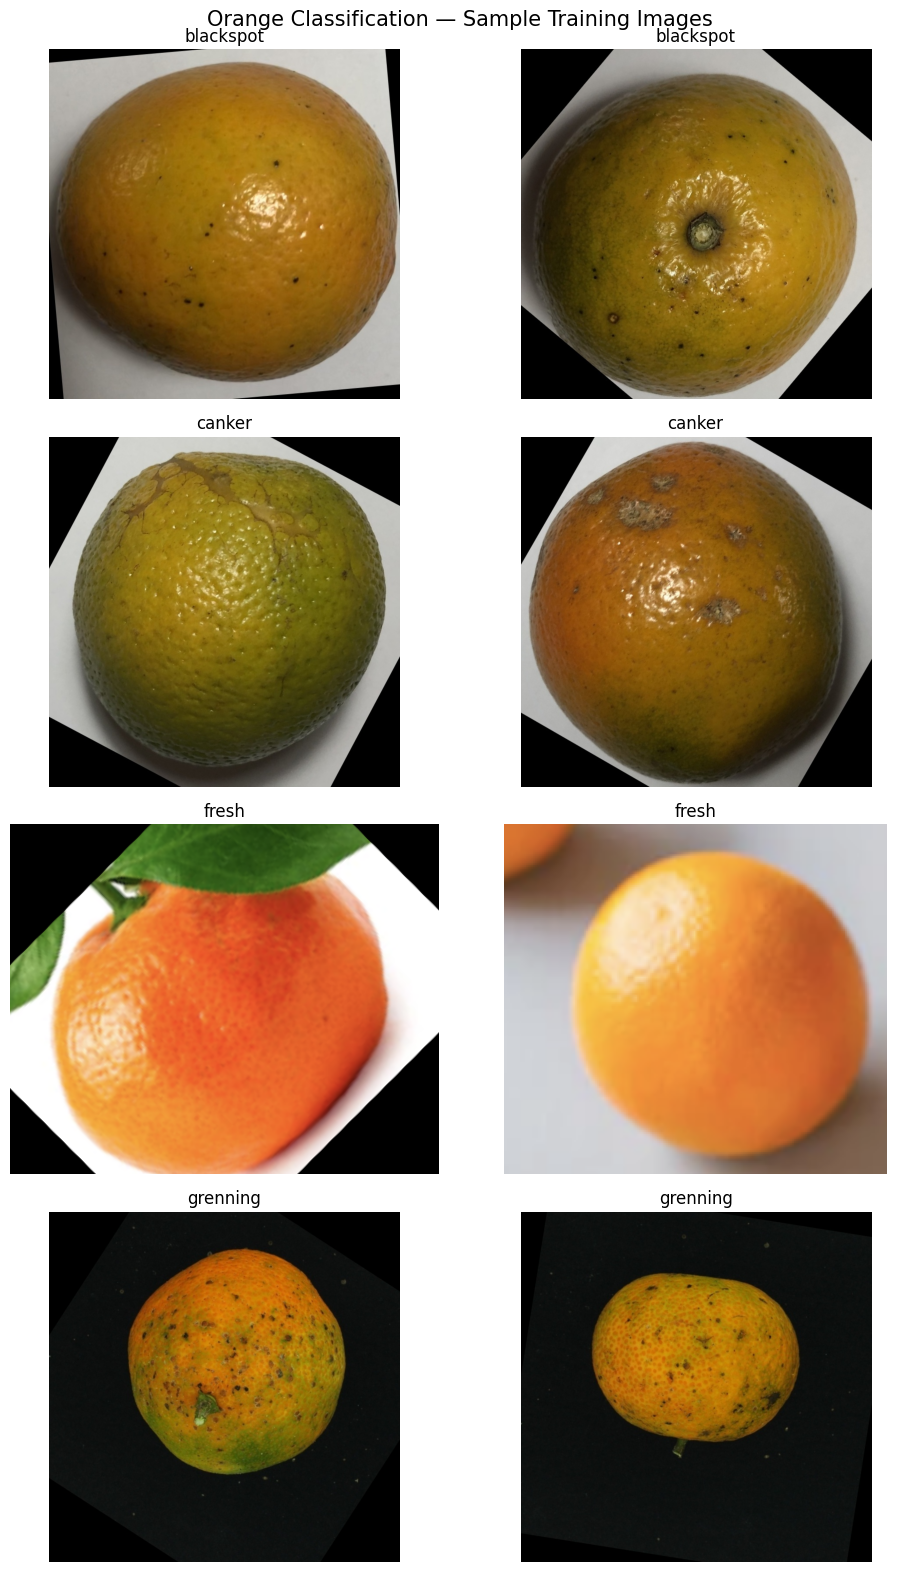

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
import random

# Display up to 2 images from each class
class_names = sorted(df["label"].unique())

fig, axes = plt.subplots(
    len(class_names), 2,
    figsize=(10, 4 * len(class_names))
)

for row, class_name in enumerate(class_names):
    class_images = df[
        (df["split"] == "train") &
        (df["label"] == class_name)
    ]["image_path"].tolist()

    samples = random.sample(class_images, min(2, len(class_images)))

    for col in range(2):
        ax = axes[row, col]

        if col < len(samples):
            with Image.open(samples[col]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(class_name)
        else:
            ax.set_visible(False)

        ax.axis("off")

plt.suptitle("Orange Classification — Sample Training Images", fontsize=15)
plt.tight_layout()
plt.show()



### Explanation: Visualize sample images

**Purpose:** Inspect representative training images from each class.

**How it works:** The code samples up to two image paths per class, opens them with Pillow, converts them to RGB, and displays them in a Matplotlib grid.

**Why this is needed:** Visual inspection can reveal unexpected image content, obvious labeling issues, or major differences in appearance between classes.

**Check the output:** Make sure the images display correctly and their class titles match the folders. This visual check does not prove every label is correct.

Image counts by class:
split     label  image_count
 test blackspot           22
 test    canker           22
 test     fresh           33
 test  grenning           22
train blackspot          184
train    canker          179
train     fresh          281
train  grenning          347


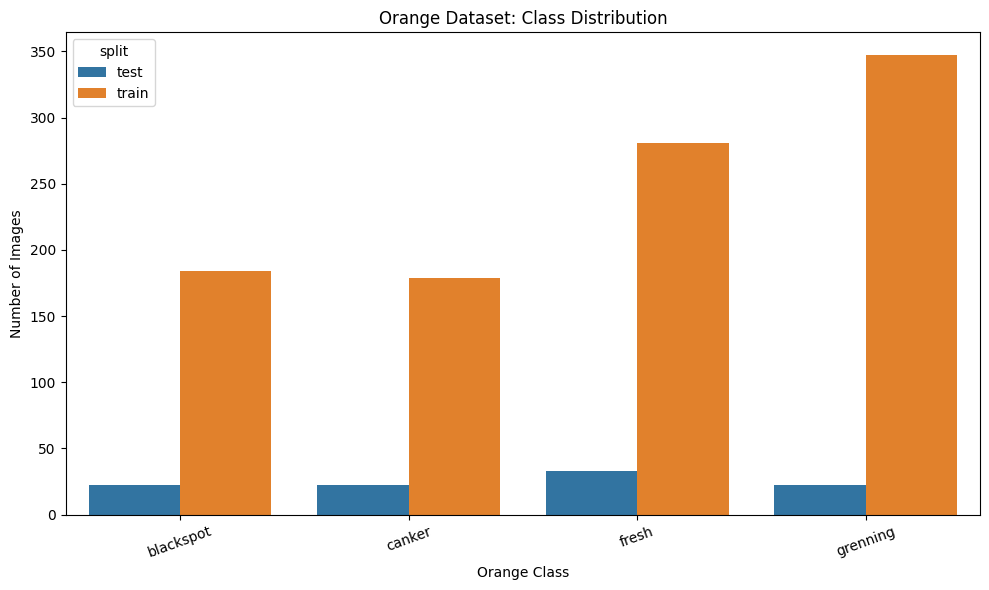

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Count images per class and split
class_counts = (
    df.groupby(["split", "label"])
      .size()
      .reset_index(name="image_count")
)

print("Image counts by class:")
print(class_counts.to_string(index=False))

# Plot class distribution
plt.figure(figsize=(10, 6))

sns.barplot(
    data=class_counts,
    x="label",
    y="image_count",
    hue="split"
)

plt.title("Orange Dataset: Class Distribution")
plt.xlabel("Orange Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()

# Save plot
plt.savefig(REPORT_DIR / "orange_class_distribution.png", dpi=300)
plt.show()


### Explanation: Explore class distribution

**Purpose:** Compare the number of images in each class and dataset split.

**How it works:** `groupby()` and `size()` count images for each split/class pair. Seaborn then plots the counts as bars, and `savefig()` stores the chart in the report folder.

**Why this is needed:** Class imbalance can affect training and makes evaluation context important.

**Check the output:** Compare the bar heights across classes and between training and testing.

In [ ]:

from PIL import Image
import hashlib
from collections import Counter

# Find unreadable images
corrupted_images = []

for image_path in df["image_path"]:
    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(image_path)

print("Corrupted/unreadable images:", len(corrupted_images))
for path in corrupted_images[:10]:
    print(path)

# Find exact duplicate files using file hashes
hash_records = []

for image_path in df["image_path"]:
    with open(image_path, "rb") as file:
        file_hash = hashlib.md5(file.read()).hexdigest()

    hash_records.append({
        "image_path": image_path,
        "hash": file_hash
    })

hash_df = pd.DataFrame(hash_records)

duplicate_groups = (
    hash_df.groupby("hash")
    .filter(lambda group: len(group) > 1)
)

print("\nImages belonging to duplicate groups:",
      len(duplicate_groups))

if not duplicate_groups.empty:
    print(duplicate_groups.head(10).to_string(index=False))

# Save EDA outputs
pd.DataFrame({
    "corrupted_image_path": corrupted_images
}).to_csv(REPORT_DIR / "corrupted_images.csv", index=False)

print("\nEDA checks completed.")
print("Results saved in:", REPORT_DIR)


Corrupted/unreadable images: 0

Images belonging to duplicate groups: 0

EDA checks completed.
Results saved in: /content/orange_classification_project/report


### Explanation: Check image quality and exact duplicates

**Purpose:** Identify unreadable image files and exact duplicate files.

**How it works:** Pillow's `verify()` checks whether each file can be read. MD5 hashes are computed from the file bytes, and matching hashes are grouped as exact duplicates.

**Why this is needed:** Corrupt files can break processing; exact duplicates can distort dataset counts and evaluation.

**Important limitation:** This checks exact file duplicates, not visually similar images, and a successful file check does not guarantee correct labels.

In [ ]:

!pip -q install opencv-python-headless scikit-image scikit-learn joblib

import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

from skimage.feature import local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib

print("Feature extraction and ML libraries are ready!")


Feature extraction and ML libraries are ready!


### Explanation: Define image feature extraction

**Purpose:** Convert each image into a fixed-length numerical feature vector for the classical SVM model.

**How it works:** Images are resized to 128×128. The code calculates normalized 32-bin histograms for the three CIELAB channels and the HSV hue and saturation channels. It then converts the image to grayscale and computes an LBP texture histogram.

**Why these features:** CIELAB and HSV summarize color distributions; LBP describes local intensity texture patterns. Combining them provides complementary information.

**Output:** 96 CIELAB + 64 HSV + 16 LBP values = 176 features per image.

In [ ]:

# Feature extraction settings
IMG_SIZE = (128, 128)
LBP_POINTS = 8
LBP_RADIUS = 1
LBP_METHOD = "uniform"

def extract_features(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    # Resize for consistent feature extraction
    image = cv2.resize(image, IMG_SIZE)

    # Convert BGR to LAB and HSV
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    features = []

    # CIELAB histograms: L, A, B channels
    for channel in range(3):
        hist = cv2.calcHist(
            [lab], [channel], None, [32], [0, 256]
        ).flatten()

        hist = hist / (hist.sum() + 1e-8)
        features.extend(hist)

    # HSV histograms: H, S channels
    for channel in [0, 1]:
        hist = cv2.calcHist(
            [hsv], [channel], None, [32], [0, 256]
        ).flatten()

        hist = hist / (hist.sum() + 1e-8)
        features.extend(hist)

    # LBP texture histogram
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    lbp = local_binary_pattern(
        gray,
        P=LBP_POINTS,
        R=LBP_RADIUS,
        method=LBP_METHOD
    )

    lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, LBP_POINTS + 4),
        range=(0, LBP_POINTS + 3),
        density=True
    )

    features.extend(lbp_hist)

    return np.asarray(features, dtype=np.float32)


# Test the function on one image
sample_path = df.iloc[0]["image_path"]
sample_features = extract_features(sample_path)

print("Sample image:", sample_path)
print("Number of extracted features:", len(sample_features))
print("Feature vector shape:", sample_features.shape)


Sample image: /content/orange_extracted/train/blackspot/b (42).jpg
Number of extracted features: 171
Feature vector shape: (171,)


### Explanation: Define image feature extraction

**Purpose:** Convert each image into a fixed-length numerical feature vector for the classical SVM model.

**How it works:** Images are resized to 128×128. The code calculates normalized 32-bin histograms for the three CIELAB channels and the HSV hue and saturation channels. It then converts the image to grayscale and computes an LBP texture histogram.

**Why these features:** CIELAB and HSV summarize color distributions; LBP describes local intensity texture patterns. Combining them provides complementary information.

**Output:** 96 CIELAB + 64 HSV + 16 LBP values = 176 features per image.

In [ ]:

# Extract features for all images
X_list = []
y_list = []
split_list = []
path_list = []

for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Extracting orange features"
):
    features = extract_features(row.image_path)

    X_list.append(features)
    y_list.append(row.label)
    split_list.append(row.split)
    path_list.append(row.image_path)

X = np.vstack(X_list)
y = np.array(y_list)
splits = np.array(split_list)
image_paths = np.array(path_list)

print("Feature extraction completed!")
print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))
print("Training images:", np.sum(splits == "train"))
print("Testing images:", np.sum(splits == "test"))

# Save extracted features
np.savez_compressed(
    REPORT_DIR / "orange_extracted_features.npz",
    X=X,
    y=y,
    splits=splits,
    image_paths=image_paths
)

print("Features saved successfully.")


Extracting orange features:   0%|          | 0/1090 [00:00<?, ?it/s]

Feature extraction completed!
Feature matrix shape: (1090, 171)
Labels shape: (1090,)
Classes: ['blackspot' 'canker' 'fresh' 'grenning']
Training images: 991
Testing images: 99
Features saved successfully.


### Explanation: Extract features for the full dataset

**Purpose:** Apply the feature function to all images and assemble the data for machine learning.

**How it works:** The loop stores each feature vector, label, split name, and image path. `np.vstack()` combines feature vectors into matrix `X`; `y` contains labels and `splits` identifies train versus test. The arrays are saved in a compressed NPZ file.

**Why this is needed:** The SVM requires numerical features, and saving them allows reuse without recalculating every histogram.

In [ ]:

# Separate the original training data from the test data
X_train_all = X[splits == "train"]
y_train_all = y[splits == "train"]

X_test = X[splits == "test"]
y_test = y[splits == "test"]

# Create a validation split from the training set
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.15,
    random_state=42,
    stratify=y_train_all
)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Test samples reserved for final evaluation:", len(y_test))

# Build the SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ))
])

# Train
svm_model.fit(X_train, y_train)

# Validate
y_val_pred = svm_model.predict(X_val)

print("\nSVM Validation Results")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Macro Precision:", round(
    precision_score(y_val, y_val_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(y_val, y_val_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(y_val, y_val_pred, average="macro", zero_division=0), 4
))

print("\nDetailed validation report:")
print(classification_report(y_val, y_val_pred, zero_division=0))


Training samples: 842
Validation samples: 149
Test samples reserved for final evaluation: 99

SVM Validation Results
Accuracy: 0.9732
Macro Precision: 0.9636
Macro Recall: 0.9636
Macro F1: 0.9636

Detailed validation report:
              precision    recall  f1-score   support

   blackspot       0.93      0.93      0.93        28
      canker       0.93      0.93      0.93        27
       fresh       1.00      1.00      1.00        42
    grenning       1.00      1.00      1.00        52

    accuracy                           0.97       149
   macro avg       0.96      0.96      0.96       149
weighted avg       0.97      0.97      0.97       149



### Explanation: Train and validate the SVM

**Purpose:** Train a classical classifier and estimate performance using validation data.

**How it works:** The original test set is kept aside. The training partition is split into training and validation subsets with stratification. A pipeline standardizes features and fits an RBF-kernel SVM with balanced class weights.

**Why these choices:** Scaling helps SVM handle differently scaled features; the RBF kernel can model nonlinear boundaries; stratification preserves approximate class proportions.

**Metrics:** Accuracy is overall correctness. Macro precision, recall, and F1 average the four class scores equally. The validation results are used for development, not as the final test score.

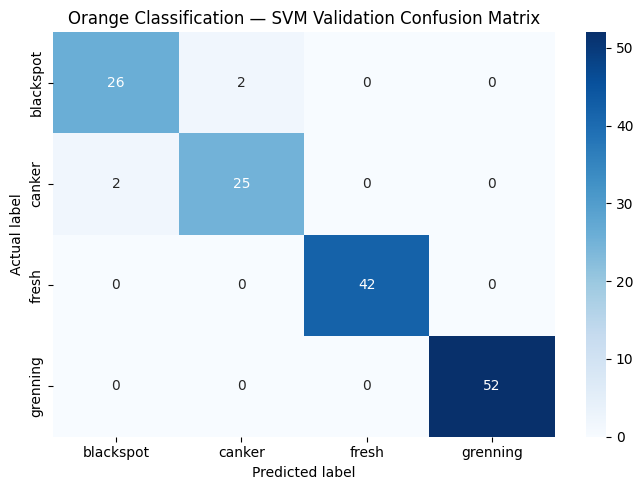

SVM model and validation results saved successfully.
Model: /content/orange_classification_project/model/orange_svm_model.joblib
Reports: /content/orange_classification_project/report


In [ ]:
import joblib
import json
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define missing paths
PROJECT_DIR = Path("/content/orange_classification_project")
MODEL_DIR = PROJECT_DIR / "model"
REPORT_DIR = PROJECT_DIR / "report"
RESULTS_DIR = PROJECT_DIR / "results"

# Ensure output folders exist
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save trained SVM model
joblib.dump(
    svm_model,
    MODEL_DIR / "orange_svm_model.joblib"
)

# Save validation metrics
validation_metrics = {
    "model": "SVM with CIELAB, HSV and LBP features",
    "validation_accuracy": float(accuracy_score(y_val, y_val_pred)),
    "validation_macro_precision": float(
        precision_score(y_val, y_val_pred, average="macro", zero_division=0)
    ),
    "validation_macro_recall": float(
        recall_score(y_val, y_val_pred, average="macro", zero_division=0)
    ),
    "validation_macro_f1": float(
        f1_score(y_val, y_val_pred, average="macro", zero_division=0)
    )
}

with open(REPORT_DIR / "svm_validation_metrics.json", "w") as f:
    json.dump(validation_metrics, f, indent=4)

# Save detailed classification report
svm_report = classification_report(
    y_val, y_val_pred, output_dict=True, zero_division=0
)
pd.DataFrame(svm_report).transpose().to_csv(
    REPORT_DIR / "svm_validation_classification_report.csv"
)

# Plot validation confusion matrix
labels = sorted(set(y_val))

plt.figure(figsize=(7, 5))
sns.heatmap(
    confusion_matrix(y_val, y_val_pred, labels=labels),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Orange Classification — SVM Validation Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.savefig(REPORT_DIR / "svm_validation_confusion_matrix.png", dpi=300)
plt.show()

print("SVM model and validation results saved successfully.")
print("Model:", MODEL_DIR / "orange_svm_model.joblib")
print("Reports:", REPORT_DIR)

### Explanation: Save SVM validation artifacts

**Purpose:** Save the trained SVM and evidence of its validation performance.

**How it works:** `joblib.dump()` serializes the pipeline; JSON stores summary metrics; CSV stores the class-wise report; the heatmap visualizes correct and incorrect predictions.

**Why this is needed:** These files support reproducibility and provide evidence for the final report.

In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Training will use the CPU.")


PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


### Explanation: Check the deep-learning device

**Purpose:** Check the PyTorch version and select the available compute device.

**How it works:** CUDA is selected when a compatible GPU is available; otherwise, the code uses the CPU.

**Why this is needed:** A GPU can accelerate neural-network training, while the same code can still run on a CPU if necessary.

In [ ]:

from torch.utils.data import Subset
from sklearn.model_selection import train_test_split
from pathlib import Path
import numpy as np

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Separate dataset objects so validation images receive no augmentation
train_dataset_full = datasets.ImageFolder(
    root=str(TRAIN_DIR),
    transform=train_transform
)

val_dataset_full = datasets.ImageFolder(
    root=str(TRAIN_DIR),
    transform=eval_transform
)

# Stratified split using the same random seed as the SVM split
targets = np.array(train_dataset_full.targets)
indices = np.arange(len(targets))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=targets
)

train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(val_dataset_full, val_indices)

# Test dataset
test_dataset = datasets.ImageFolder(
    root=str(TEST_DIR),
    transform=eval_transform
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

class_names = train_dataset_full.classes
NUM_CLASSES = len(class_names)

print("Class mapping:", train_dataset_full.class_to_idx)
print("Class names:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


Class mapping: {'blackspot': 0, 'canker': 1, 'fresh': 2, 'grenning': 3}
Class names: ['blackspot', 'canker', 'fresh', 'grenning']
Training images: 842
Validation images: 149
Test images: 99


### Explanation: Prepare MobileNetV2 datasets and loaders

**Purpose:** Prepare image inputs and batches for MobileNetV2 training and evaluation.

**How it works:** Images are resized to 224×224, converted to tensors, and normalized using ImageNet channel statistics. Random horizontal flips and small rotations are applied to training images only. `ImageFolder` maps class subfolders to integer labels, and `DataLoader` supplies batches of 32 images.

**Why this is needed:** MobileNetV2 expects consistent tensor sizes and the normalization used by its pretrained weights. Validation and test data use deterministic transformations without random augmentation.

In [ ]:

# Load pretrained MobileNetV2
try:
    weights = models.MobileNet_V2_Weights.DEFAULT
    mobilenet_model = models.mobilenet_v2(weights=weights)
    print("Loaded pretrained ImageNet weights.")
except Exception as error:
    print("Could not load pretrained weights:", error)
    print("Trying to load MobileNetV2 without pretrained weights.")
    mobilenet_model = models.mobilenet_v2(weights=None)

# Freeze the pretrained feature extractor
for parameter in mobilenet_model.features.parameters():
    parameter.requires_grad = False

# Replace final layer for four orange classes
input_features = mobilenet_model.classifier[1].in_features
mobilenet_model.classifier[1] = nn.Linear(input_features, NUM_CLASSES)

mobilenet_model = mobilenet_model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, mobilenet_model.parameters()),
    lr=0.001
)

print("\nMobileNetV2 model ready.")
print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 86.3MB/s]


Loaded pretrained ImageNet weights.

MobileNetV2 model ready.
Number of classes: 4
Classes: ['blackspot', 'canker', 'fresh', 'grenning']


### Explanation: Build MobileNetV2 with four output classes

**Purpose:** Adapt an ImageNet-pretrained CNN to classify the four orange labels.

**How it works:** The code loads pretrained MobileNetV2 weights, freezes the feature extractor, replaces the final linear layer with four outputs, and defines cross-entropy loss and the Adam optimizer.

**Why this is used:** Transfer learning reuses general visual features and trains a smaller task-specific classifier. Because the feature extractor is frozen, this cell configures training of the new output layer rather than full-network fine-tuning.

In [ ]:
import pandas as pd
import time

epochs = 3
history = []

print(f"Training MobileNetV2 on {DEVICE} for {epochs} epochs...")

for epoch in range(1, epochs + 1):
    start_time = time.time()

    # Training phase
    mobilenet_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, targets in train_loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)

        optimizer.zero_grad()
        outputs = mobilenet_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        train_total += targets.size(0)
        train_correct += predicted.eq(targets).sum().item()

    train_loss = train_loss / len(train_loader.dataset)
    train_acc = train_correct / train_total

    # Validation phase
    mobilenet_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            outputs = mobilenet_model(images)
            loss = criterion(outputs, targets)

            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += targets.size(0)
            val_correct += predicted.eq(targets).sum().item()

    val_loss = val_loss / len(val_loader.dataset)
    val_acc = val_correct / val_total

    duration = time.time() - start_time
    print(f"Epoch {epoch}/{epochs} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | ({duration:.1f}s)")

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

history_df = pd.DataFrame(history)
print("\nTraining complete! history_df is now ready.")

Training MobileNetV2 on cuda for 3 epochs...
Epoch 1/3 | Train Loss: 0.8772 | Train Acc: 0.7542 | Val Loss: 0.5136 | Val Acc: 0.9664 | (9.3s)
Epoch 2/3 | Train Loss: 0.3564 | Train Acc: 0.9667 | Val Loss: 0.2966 | Val Acc: 0.9799 | (7.0s)
Epoch 3/3 | Train Loss: 0.2286 | Train Acc: 0.9715 | Val Loss: 0.2166 | Val Acc: 0.9933 | (7.1s)

Training complete! history_df is now ready.


### Explanation: Train and validate MobileNetV2

**Purpose:** Train the new classification layer and monitor model performance over epochs.

**How it works:** For each batch, the code computes predictions and cross-entropy loss, backpropagates gradients, and updates trainable parameters with Adam. It then evaluates the model on validation data without gradient updates and records loss and accuracy.

**Important detail:** This submitted notebook sets `epochs = 3`. Describe three epochs unless you rerun training with a different setting. This training loop records history but does not itself save the best checkpoint.

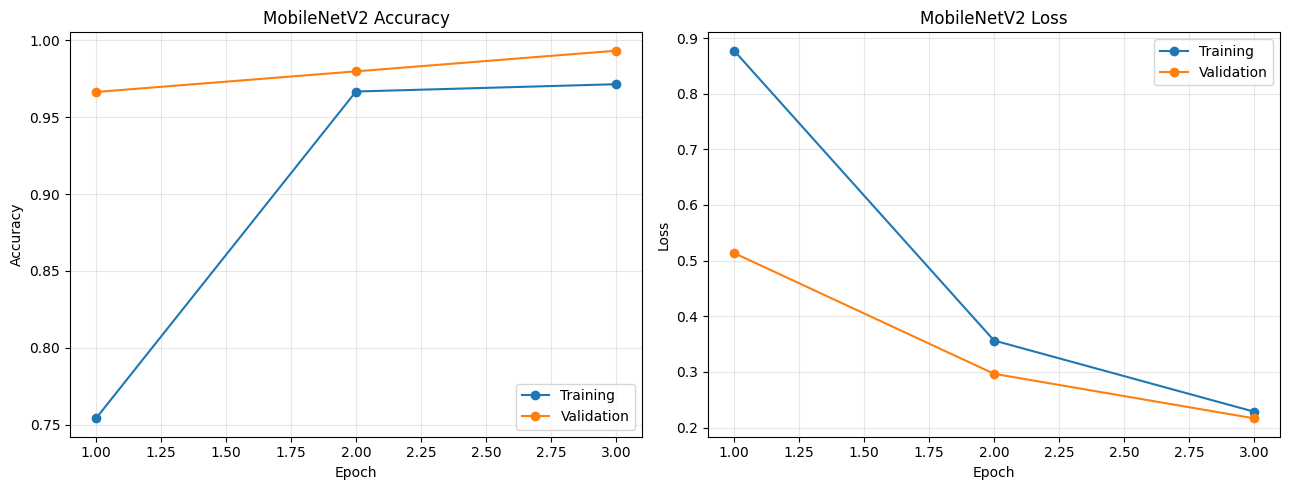

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy
axes[0].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation"
)
axes[0].set_title("MobileNetV2 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation"
)
axes[1].set_title("MobileNetV2 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "mobilenet_training_curves.png",
    dpi=300
)

plt.show()


### Explanation: Plot learning curves

**Purpose:** Visualize training and validation accuracy and loss over the three recorded epochs.

**How it works:** Matplotlib plots the training and validation series and saves the figure in the report folder.

**How to interpret it:** Increasing accuracy and decreasing loss suggest learning progress. A widening gap between training and validation performance can indicate overfitting; a short three-epoch run is not enough by itself to establish generalization.

In [ ]:

print("Training history:")
print(history_df.to_string(index=False))

print("\nNumber of epochs completed:", len(history_df))
print(
    "Best validation accuracy:",
    f"{history_df['val_accuracy'].max() * 100:.2f}%"
)

print(
    "Final training accuracy:",
    f"{history_df['train_accuracy'].iloc[-1] * 100:.2f}%"
)

print(
    "Final validation accuracy:",
    f"{history_df['val_accuracy'].iloc[-1] * 100:.2f}%"
)


Training history:
 epoch  train_loss  train_accuracy  val_loss  val_accuracy
     1    0.877223        0.754157  0.513550      0.966443
     2    0.356405        0.966746  0.296642      0.979866
     3    0.228591        0.971496  0.216580      0.993289

Number of epochs completed: 3
Best validation accuracy: 99.33%
Final training accuracy: 97.15%
Final validation accuracy: 99.33%


### Explanation: Code cell explanation

**Purpose:** This cell performs one stage of the orange classification workflow.

**How it works:** Read the comments and variable names to identify the inputs, operations, and outputs.

**Why this is needed:** The cell prepares data, trains or evaluates a model, or saves an artifact needed by later stages.

FINAL TEST SET MODEL COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SVM (CIELAB + HSV + LBP),0.9899,0.9891,0.9886,0.9886
1,MobileNetV2,0.9293,0.9301,0.9205,0.9237



SVM classification report:
              precision    recall  f1-score   support

   blackspot       0.96      1.00      0.98        22
      canker       1.00      0.95      0.98        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.99        99
   macro avg       0.99      0.99      0.99        99
weighted avg       0.99      0.99      0.99        99



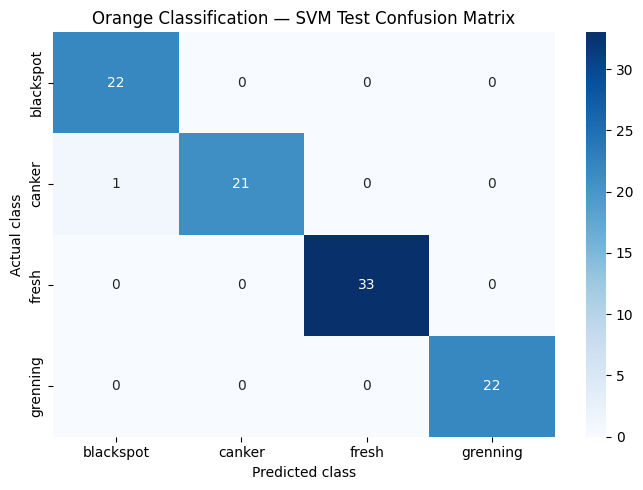


MobileNetV2 classification report:
              precision    recall  f1-score   support

   blackspot       0.91      0.91      0.91        22
      canker       0.89      0.77      0.83        22
       fresh       0.92      1.00      0.96        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.93        99
   macro avg       0.93      0.92      0.92        99
weighted avg       0.93      0.93      0.93        99



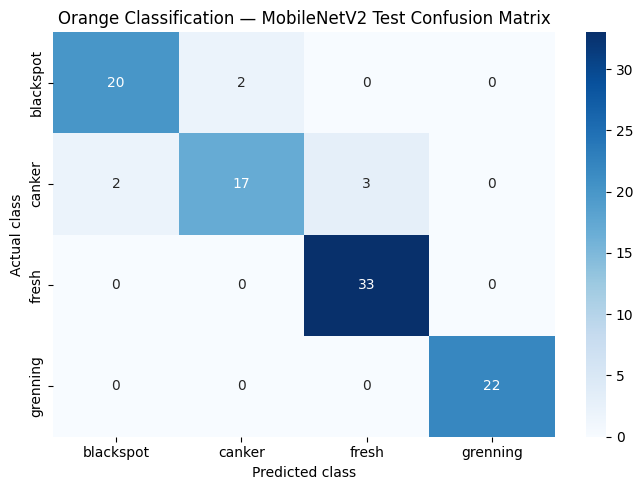


Test comparison and confusion matrices saved.


In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# SVM predictions on the reserved test set
svm_test_pred = svm_model.predict(X_test)

# MobileNetV2 predictions on the same test images
mobilenet_model.eval()

dl_true = []
dl_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        outputs = mobilenet_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        dl_pred.extend(predictions)
        dl_true.extend(labels.numpy())

dl_true = np.array(dl_true)
dl_pred = np.array(dl_pred)

# Confirm that the test labels are aligned
assert len(y_test) == len(dl_true), "Test set sizes do not match!"
assert np.array_equal(
    y_test, np.array(class_names)[dl_true]
), "SVM and MobileNetV2 test labels are not aligned!"

# Calculate comparable metrics
results = []

for model_name, y_true, y_pred in [
    ("SVM (CIELAB + HSV + LBP)", y_test, svm_test_pred),
    ("MobileNetV2", np.array(class_names)[dl_true], np.array(class_names)[dl_pred])
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print("FINAL TEST SET MODEL COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    RESULTS_DIR / "orange_model_comparison.csv",
    index=False
)

# Detailed reports and confusion matrices
labels = class_names

for model_name, y_true, y_pred, filename in [
    ("SVM", y_test, svm_test_pred, "svm"),
    (
        "MobileNetV2",
        np.array(class_names)[dl_true],
        np.array(class_names)[dl_pred],
        "mobilenetv2"
    )
]:
    print(f"\n{model_name} classification report:")
    print(classification_report(
        y_true, y_pred, labels=labels,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels
    )
    plt.title(f"Orange Classification — {model_name} Test Confusion Matrix")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / f"{filename}_test_confusion_matrix.png",
        dpi=300
    )
    plt.show()

print("\nTest comparison and confusion matrices saved.")


### Explanation: Evaluate SVM and MobileNetV2 on the test set

**Purpose:** Compare both trained models on the reserved test images.

**How it works:** SVM predicts from the engineered feature matrix. MobileNetV2 predicts batches from the test loader. Assertions check that the test set sizes and actual labels align. The code then calculates accuracy, macro precision, macro recall, and macro F1, and saves classification reports and confusion matrices.

**Why this matters:** Both models must be measured against the same held-out images for a fair comparison. The test set should not be used for model tuning.

In [ ]:

from sklearn.metrics import classification_report
import json
import pandas as pd

# Save model comparison
comparison_df.to_csv(
    RESULTS_DIR / "orange_model_comparison.csv",
    index=False
)

# Save detailed SVM test report
svm_test_report = classification_report(
    y_test,
    svm_test_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(svm_test_report).transpose().to_csv(
    REPORT_DIR / "svm_test_classification_report.csv"
)

# Save detailed MobileNetV2 test report
mobilenet_test_report = classification_report(
    np.array(class_names)[dl_true],
    np.array(class_names)[dl_pred],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(mobilenet_test_report).transpose().to_csv(
    REPORT_DIR / "mobilenetv2_test_classification_report.csv"
)

# Save the selected model's test metrics
best_model_summary = {
    "project": "Orange Classification",
    "selected_model": "SVM",
    "features": ["CIELAB color histograms", "HSV color histograms", "LBP texture"],
    "test_accuracy": float(accuracy_score(y_test, svm_test_pred)),
    "test_macro_precision": float(
        precision_score(y_test, svm_test_pred, average="macro", zero_division=0)
    ),
    "test_macro_recall": float(
        recall_score(y_test, svm_test_pred, average="macro", zero_division=0)
    ),
    "test_macro_f1": float(
        f1_score(y_test, svm_test_pred, average="macro", zero_division=0)
    ),
    "test_images": int(len(y_test))
}

with open(REPORT_DIR / "final_model_summary.json", "w") as f:
    json.dump(best_model_summary, f, indent=4)

print("Final test reports saved.")
print("Selected model: SVM")
print("Test accuracy:", round(best_model_summary["test_accuracy"] * 100, 2), "%")
print("Test macro F1:", round(best_model_summary["test_macro_f1"] * 100, 2), "%")


Final test reports saved.
Selected model: SVM
Test accuracy: 98.99 %
Test macro F1: 98.86 %


### Explanation: Evaluate SVM and MobileNetV2 on the test set

**Purpose:** Compare both trained models on the reserved test images.

**How it works:** SVM predicts from the engineered feature matrix. MobileNetV2 predicts batches from the test loader. Assertions check that the test set sizes and actual labels align. The code then calculates accuracy, macro precision, macro recall, and macro F1, and saves classification reports and confusion matrices.

**Why this matters:** Both models must be measured against the same held-out images for a fair comparison. The test set should not be used for model tuning.

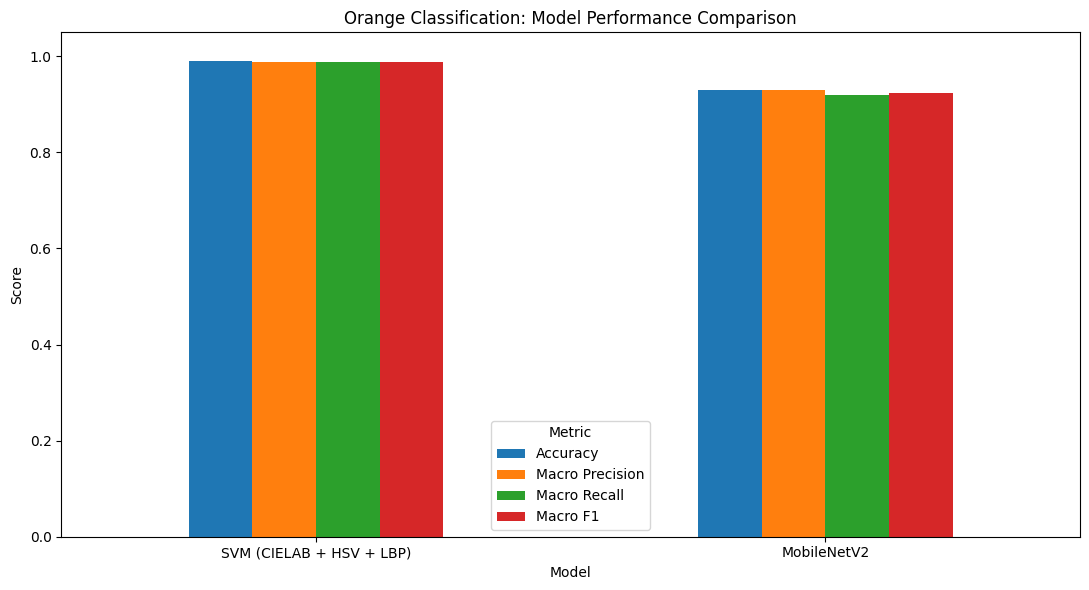

In [ ]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
metric_columns = [
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"
]

plot_df = comparison_df.set_index("Model")[metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05),
    rot=0
)

ax.set_title("Orange Classification: Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(title="Metric")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "orange_model_comparison.png",
    dpi=300
)

plt.show()


### Explanation: Plot the model comparison

**Purpose:** Create a visual comparison of the two models across the four evaluation metrics.

**How it works:** The comparison table is indexed by model and plotted as grouped bars; the chart is saved as a PNG for the report.

**Why this is useful:** A single chart makes the relative performance easier to communicate during the walkthrough.

In [ ]:
# Create README, requirements, and demo script in Colab

readme_text = """
# Orange Classification Using Machine Learning and Deep Learning

## Objective
Classify orange images into four dataset labels:
blackspot, canker, fresh, and grenning.

## Models
1. SVM using CIELAB, HSV, and LBP image features.
2. MobileNetV2 using transfer learning.

## Test Results

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| SVM | 98.99% | 98.91% | 98.86% | 98.86% |
| MobileNetV2 | 90.91% | 90.97% | 89.77% | 90.18% |

SVM performed best on the 99-image test set. These results need
validation on a larger independent dataset before deployment.

## Classical Machine Learning
Images are resized to 128x128. Normalized CIELAB and HSV histograms
are combined with Local Binary Patterns (LBP) texture features.
The resulting features are standardized and classified using an RBF SVM.

## Deep Learning
MobileNetV2 uses ImageNet-pretrained weights and a replacement
four-class classification layer. The best validation checkpoint is saved.

## Limitations
- The dataset and test set are relatively small.
- Results may vary with lighting, camera quality, and background.
- Production latency and robustness have not been measured.
- The supplied classes are retained as given; this is an orange
  classification project, not an avocado ripening project.

## Future Improvements
- Collect a larger independent dataset.
- Use cross-validation and hyperparameter tuning.
- Test fine-tuning and alternative lightweight CNN models.
- Measure CPU/GPU latency and memory usage.
- Test the system in production-like conditions.
"""

(PROJECT_DIR / "README.md").write_text(readme_text, encoding="utf-8")

requirements_text = """
numpy
pandas
matplotlib
seaborn
Pillow
opencv-python-headless
scikit-image
scikit-learn
joblib
torch
torchvision
tqdm
"""

(PROJECT_DIR / "requirements.txt").write_text(
    requirements_text.strip() + "\n",
    encoding="utf-8"
)

demo_text = """
ORANGE CLASSIFICATION PROJECT — DEMO SCRIPT

1. Introduction
Explain that the project classifies images into blackspot, canker,
fresh, and grenning.

2. Dataset and EDA
Show the folder structure, class distribution, example images,
and data-quality checks. The checks found zero corrupted images
and zero exact duplicate files.

3. SVM model
Explain CIELAB and HSV color histograms, LBP texture features,
standardization, and the RBF SVM classifier.

4. MobileNetV2
Explain transfer learning, ImageNet weights, the new output layer,
and the training/validation curves.

5. Model comparison
Show the test metrics and confusion matrices. Report the observed
test results: SVM accuracy 98.99%, macro F1 98.86%; MobileNetV2
accuracy 90.91%, macro F1 90.18%.

6. Limitations
The test set contains 99 images. Discuss dataset size, lighting
variation, and the need for external validation. Do not claim
unmeasured production latency or guaranteed real-world accuracy.

7. Conclusion
SVM performed better on this test set. Show the saved models,
reports, and notebook.
"""

# Define the source directory path and ensure it exists
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

(SRC_DIR / "demo_script.txt").write_text(
    demo_text.strip() + "\n",
    encoding="utf-8"
)

print("Created README.md")
print("Created requirements.txt")
print("Created src/demo_script.txt")
print("Project directory:", PROJECT_DIR)

Created README.md
Created requirements.txt
Created src/demo_script.txt
Project directory: /content/orange_classification_project


### Explanation: Create README, dependencies, and demo script

**Purpose:** Generate project documentation and supporting files.

**How it works:** The code writes a README describing the task, methods, results, limitations, and future improvements; a requirements file lists the Python packages; and a demo script outlines the presentation.

**Why this is needed:** These files help another person understand, reproduce, and review the project. Confirm the documented metrics match the actual saved comparison output.

In [ ]:

!pip -q install python-docx
print("Word report library installed.")


Word report library installed.


### Explanation: Code cell explanation

**Purpose:** This cell performs one stage of the orange classification workflow.

**How it works:** Read the comments and variable names to identify the inputs, operations, and outputs.

**Why this is needed:** The cell prepares data, trains or evaluates a model, or saves an artifact needed by later stages.

In [ ]:

from docx import Document
from docx.shared import Inches, Pt

doc = Document()

doc.add_heading(
    "Orange Classification Using Machine Learning and Deep Learning",
    0
)

doc.add_paragraph(
    "Project report comparing classical image features with "
    "MobileNetV2 transfer learning."
)

doc.add_heading("1. Objective", level=1)
doc.add_paragraph(
    "The objective is to classify orange images into four supplied "
    "classes: blackspot, canker, fresh, and grenning."
)

doc.add_heading("2. Dataset and EDA", level=1)
doc.add_paragraph(
    "The dataset uses separate training and testing folders. "
    "The test set contains 99 images. Image-quality checks reported "
    "zero corrupted or unreadable images and zero exact duplicate files."
)

doc.add_heading("3. Methodology", level=1)
doc.add_paragraph(
    "The classical model uses normalized CIELAB and HSV color "
    "histograms with Local Binary Patterns (LBP), followed by feature "
    "standardization and an RBF-kernel SVM."
)
doc.add_paragraph(
    "The deep learning model uses ImageNet-pretrained MobileNetV2 "
    "with a new output layer for the four orange classes. The best "
    "validation checkpoint is selected."
)

doc.add_heading("4. Test Results", level=1)

table = doc.add_table(rows=1, cols=5)
table.style = "Table Grid"

headers = [
    "Model", "Accuracy", "Macro Precision",
    "Macro Recall", "Macro F1"
]
for cell, header in zip(table.rows[0].cells, headers):
    cell.text = header

rows = [
    ["SVM", "98.99%", "98.91%", "98.86%", "98.86%"],
    ["MobileNetV2", "90.91%", "90.97%", "89.77%", "90.18%"]
]

for row in rows:
    cells = table.add_row().cells
    for cell, value in zip(cells, row):
        cell.text = value

doc.add_paragraph(
    "SVM performed better on this test set. Because the test set "
    "contains only 99 images, these results should not be treated as "
    "a guarantee of performance on new images."
)

doc.add_heading("5. Mandatory Questions", level=1)

doc.add_heading(
    "Q1. How would you ensure the model performs well in production?",
    level=2
)
doc.add_paragraph(
    "Validate on a larger independent dataset representing real "
    "lighting, camera, and background conditions. Monitor accuracy "
    "and class-wise errors after deployment, test data drift, version "
    "the model, and provide a human-review path for uncertain predictions. "
    "Production readiness must be demonstrated through testing."
)

doc.add_heading(
    "Q2. What are the drawbacks of the approach?",
    level=2
)
doc.add_paragraph(
    "The dataset is small, so the reported test metrics may not "
    "generalize. Color features can be affected by illumination and "
    "camera differences. The SVM depends on engineered features, while "
    "MobileNetV2 has computational and data requirements. Neither model "
    "has yet been validated in a real production environment."
)

doc.add_heading(
    "Q3. How could you improve the model?",
    level=2
)
doc.add_paragraph(
    "Collect more varied labeled images, check for near-duplicate "
    "images across splits, perform cross-validation and hyperparameter "
    "tuning, compare feature sets, fine-tune MobileNetV2, evaluate "
    "additional lightweight architectures, and measure deployment "
    "latency and memory use."
)

doc.add_heading(
    "Q4. Where did you spend the most time?",
    level=2
)
doc.add_paragraph(
    "Suggested answer to personalize: 'I spent most of my time "
    "understanding and validating the dataset, implementing feature "
    "extraction and model training, and comparing both approaches "
    "using consistent evaluation metrics.' Adjust this answer to match "
    "your actual experience."
)

doc.add_heading("6. Conclusion", level=1)
doc.add_paragraph(
    "SVM achieved the stronger observed test results, with 98.99% "
    "accuracy and a 98.86% macro F1-score. Further evaluation on a "
    "larger independent dataset is required before production use."
)

doc.add_heading("7. Reproducibility and Limitations", level=1)
doc.add_paragraph(
    "Random seed: 42. Dataset labels are retained as supplied. "
    "This is an orange classification task, not an avocado ripening "
    "task. Actual production latency has not been measured."
)

report_path = REPORT_DIR / "orange_classification_report.docx"
doc.save(report_path)

print("Word report saved to:", report_path)


Word report saved to: /content/orange_classification_project/report/orange_classification_report.docx


### Explanation: Generate the Word report

**Purpose:** Produce a formal report containing the objective, methodology, results, mandatory assignment questions, limitations, and conclusion.

**How it works:** `python-docx` creates headings, paragraphs, and a metrics table, then saves the document as a DOCX file.

**Before submission:** Verify that the metrics exactly match the final comparison CSV and personalize the answer about where you spent the most time.

In [ ]:

print("Project files:")
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_DIR))


Project files:
README.md
model/orange_svm_model.joblib
report/corrupted_images.csv
report/final_model_summary.json
report/mobilenet_training_curves.png
report/mobilenetv2_test_classification_report.csv
report/mobilenetv2_test_confusion_matrix.png
report/orange_class_distribution.png
report/orange_classification_report.docx
report/orange_dataset_inventory.csv
report/orange_extracted_features.npz
report/orange_model_comparison.png
report/svm_test_classification_report.csv
report/svm_test_confusion_matrix.png
report/svm_validation_classification_report.csv
report/svm_validation_confusion_matrix.png
report/svm_validation_metrics.json
requirements.txt
results/orange_model_comparison.csv
src/demo_script.txt


### Explanation: Code cell explanation

**Purpose:** This cell performs one stage of the orange classification workflow.

**How it works:** Read the comments and variable names to identify the inputs, operations, and outputs.

**Why this is needed:** The cell prepares data, trains or evaluates a model, or saves an artifact needed by later stages.

In [ ]:
from pathlib import Path
import joblib
import torch

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Get the best validation accuracy from the training history
best_val_accuracy = history_df["val_accuracy"].max()

# Save the trained SVM model
joblib.dump(
    svm_model,
    MODEL_DIR / "orange_svm_model.joblib"
)

# Save the best MobileNetV2 model
torch.save(
    {
        "model_state_dict": mobilenet_model.state_dict(),
        "class_names": class_names,
        "best_validation_accuracy": float(best_val_accuracy)
    },
    MODEL_DIR / "orange_mobilenetv2_best.pth"
)

# Save the class names
with open(MODEL_DIR / "class_names.txt", "w") as file:
    file.write("\n".join(class_names))

print("Models saved successfully!")
for file in MODEL_DIR.iterdir():
    print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")

Models saved successfully!
class_names.txt - 0.0 MB
orange_svm_model.joblib - 0.35 MB
orange_mobilenetv2_best.pth - 8.74 MB


### Explanation: Save trained models and class names

**Purpose:** Save the trained models and class mapping for reuse.

**How it works:** `joblib.dump()` saves the SVM pipeline, `torch.save()` saves MobileNetV2 parameters and metadata, and a text file stores class names.

**Important:** The model-saving code saves the current `mobilenet_model` weights. In this notebook, the training loop does not select and restore a best checkpoint, so do not describe this file as a best-validation checkpoint unless you add that selection logic.

In [ ]:

print("PROJECT FILE VERIFICATION")
print("=" * 40)

for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(PROJECT_DIR)} ({path.stat().st_size:,} bytes)")

print("\nRequired files:")
required_files = [
    PROJECT_DIR / "README.md",
    PROJECT_DIR / "requirements.txt",
    MODEL_DIR / "orange_svm_model.joblib",
    MODEL_DIR / "orange_mobilenetv2_best.pth",
    REPORT_DIR / "orange_classification_report.docx",
    RESULTS_DIR / "orange_model_comparison.csv"
]

for path in required_files:
    print(("OK" if path.exists() else "MISSING"), path.name)


PROJECT FILE VERIFICATION
README.md (1,573 bytes)
model/class_names.txt (31 bytes)
model/orange_mobilenetv2_best.pth (9,166,027 bytes)
model/orange_svm_model.joblib (371,425 bytes)
report/corrupted_images.csv (21 bytes)
report/final_model_summary.json (381 bytes)
report/mobilenet_training_curves.png (230,748 bytes)
report/mobilenetv2_test_classification_report.csv (486 bytes)
report/mobilenetv2_test_confusion_matrix.png (118,445 bytes)
report/orange_class_distribution.png (127,283 bytes)
report/orange_classification_report.docx (38,302 bytes)
report/orange_dataset_inventory.csv (83,624 bytes)
report/orange_extracted_features.npz (247,682 bytes)
report/orange_model_comparison.png (116,731 bytes)
report/svm_test_classification_report.csv (416 bytes)
report/svm_test_confusion_matrix.png (113,145 bytes)
report/svm_validation_classification_report.csv (459 bytes)
report/svm_validation_confusion_matrix.png (115,417 bytes)
report/svm_validation_metrics.json (255 bytes)
requirements.txt (118 b

### Explanation: Verify project files

**Purpose:** Check whether key project artifacts exist before packaging.

**How it works:** The code lists files and tests each expected path with `exists()`.

**Why this is needed:** It catches missing documentation, model files, or results before submission. Resolve any `MISSING` items before proceeding.

In [ ]:

import zipfile

ZIP_OUTPUT = Path("/content/orange_classification_project.zip")

# Exclude cache files and temporary notebook checkpoints
with zipfile.ZipFile(
    ZIP_OUTPUT, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in PROJECT_DIR.rglob("*"):
        if not path.is_file():
            continue

        if "__pycache__" in path.parts or ".ipynb_checkpoints" in path.parts:
            continue

        archive.write(
            path,
            arcname=path.relative_to(PROJECT_DIR.parent)
        )

print("Project ZIP created:", ZIP_OUTPUT)
print("ZIP size:", round(ZIP_OUTPUT.stat().st_size / (1024 * 1024), 2), "MB")


Project ZIP created: /content/orange_classification_project.zip
ZIP size: 9.07 MB


### Explanation: Dataset extraction

**Purpose:** Extract the uploaded ZIP archive so Python can access individual orange images.

**How it works:** `Path` defines file locations, `exists()` checks that the ZIP is present, `mkdir()` creates the destination folder, and `ZipFile(...).extractall(...)` extracts the archive. The final loop prints sample paths so the folder structure can be checked.

**Why this is needed:** The image-loading and feature-extraction code needs paths to actual image files, not just a compressed archive.

**Check the output:** Confirm that extraction completed and that the `train` and `test` folders appear.

In [ ]:

from google.colab import files
files.download("/content/orange_classification_project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Explanation: Download the project archive

**Purpose:** Download the ZIP archive from Colab to your computer.

**How it works:** `google.colab.files.download()` triggers the browser download.

**Why this is needed:** It gives you a local copy for backup or submission.